In [1]:
import numpy as np 
import pandas as pd
from sklearn.feature_selection import SelectKBest,f_regression,RFE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report 
import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.tree import DecisionTreeClassifier 
from sklearn.tree import plot_tree






df = pd.read_csv('machine_service_risk.csv')
target = df["Major_Service_Required"]

print(target.skew())

df = df.drop(columns=["Asset_ID","Major_Service_Required"])

#print(df['Intermittent_Shutdown'].value_counts())
df['Intermittent_Shutdown'] = df['Intermittent_Shutdown'].map({'Yes':1,'No':0})
#print(df['Intermittent_Shutdown'].value_counts())


df['Maintenance_Plan'] = df['Maintenance_Plan'].fillna("Unknown")


df['Dust_Exposure_Level'] = df['Dust_Exposure_Level'].map({'High':1,'Low':0})


#print(df)
#print(df.describe())




df['Service_Contract'] = df['Service_Contract'].map({'Standard':1,'Extended':0})

df = pd.get_dummies(df ,columns=['Operating_Zone','Maintenance_Plan'], dtype=int)





scaler_potential = ['Average_Load_Tonnes','Equipment_Age_Months','Daily_Operating_Hours','Weekly_Idle_Hours','Lubrication_Quality_Score']
"""
for column in scaler_potential:
    print("skewnes ",df[column].skew())
    print(df[column].describe())
"""


k= 8 

selector =SelectKBest(score_func=f_regression,k=k)
X_selected = selector.fit_transform(df, target)


selected_indices = np.argsort(selector.scores_)[::-1][:k]
selected_features = df.columns[selected_indices]

# Print the selected features
"""
print("Selected Features:")
print(selected_features," score ",selected_indices )


X_train,X_test,y_train,y_test = train_test_split(df,target,test_size=0.3,random_state=42)


model = LogisticRegression(max_iter=30000)

rfe = RFE(estimator=model, n_features_to_select=8)
rfe.fit(X_train, y_train)

# Predict and evaluate
y_pred = rfe.predict(X_test)


features = rfe.support_
"""

"""
print("Selected features:", features)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
"""
RFE_features = ['Mechanical_Condition_Score', 'Maintenance_Compliance_Score',     'Error_Log_Alert', 'Sensor_Health_Score', 'Irregular_Vibration_Alert',       'Cooling_Efficiency_Score', 'Coolant_Temperature_C',      'Maintenance_Plan_Unknown']
X_train,X_test,y_train,y_test = train_test_split(df[RFE_features],target,test_size=0.25,random_state=42,    stratify=target   )

params = {
    'objective':'binary:logistic',
    'max_depth':5,
    'learning_rate':0.1,
    'n_estimators':100,
    'alpha':10
}

model = XGBClassifier(**params)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


"""
scaler = StandardScaler()
Scaler_X_train = scaler.fit_transform(X_train)
Scaler_X_test = scaler.transform(X_test)


regression_model =  LogisticRegression(max_iter=10000)

regression_model.fit(Scaler_X_train, y_train)
y_pred = regression_model.predict(Scaler_X_test)


print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train, y_train)
y_pred = decision_tree.predict(X_test)
print(y_pred)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

"""













"""
Selected Features:
Index(['Mechanical_Condition_Score', 'Maintenance_Compliance_Score',
       'Error_Log_Alert', 'Sensor_Health_Score', 'Irregular_Vibration_Alert',
       'Cooling_Efficiency_Score', 'Coolant_Temperature_C',
       'Maintenance_Plan_Unknown'],
      dtype='str')  score  [21 24 22 20 23  7 18 37]
Selected features: [False False False False False False False False False False  True False
 False False False False False False False False False  True  True  True
  True False False False False False False False  True  True False False
  True False]
Test Accuracy: 0.786046511627907

"\nSelected Features:\nIndex(['Mechanical_Condition_Score', 'Maintenance_Compliance_Score',\n       'Error_Log_Alert', 'Sensor_Health_Score', 'Irregular_Vibration_Alert',\n       'Cooling_Efficiency_Score', 'Coolant_Temperature_C',\n       'Maintenance_Plan_Unknown'],\n      dtype='str')  score  [21 24 22 20 23  7 18 37]\nSelected features: [False False False False False False False False False False  True False\n False False False False False False False False False  True  True  True\n  True False False False False False False False  True  True False False\n  True False]\nTest Accuracy: 0.786046511627907\n"


f_reggression
['Mechanical_Condition_Score', 'Maintenance_Compliance_Score',
       'Error_Log_Alert', 'Sensor_Health_Score', 'Irregular_Vibration_Alert',
       'Cooling_Efficiency_Score', 'Coolant_Temperature_C',
       'Maintenance_Plan_Unknown'],



LogisticRegression 
RFE = ['Mechanical_Condition_Score', 'Maintenance_Compliance_Score',     'Error_Log_Alert', 'Sensor_Health_Score', 'Irregular_Vibration_Alert',       'Cooling_Efficiency_Score', 'Coolant_Temperature_C',      'Maintenance_Plan_Unknown']


logicregress ion accuracy
Accuracy: 0.8364312267657993

Confusion Matrix:
 [
 [306  42]
 [ 46 144]]


Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.88      0.87       348
           1       0.77      0.76      0.77       190

    accuracy                           0.84       538
   macro avg       0.82      0.82      0.82       538
weighted avg       0.84      0.84      0.84       538


Decion treee

Accuracy: 0.912639405204461

Confusion Matrix:
 [[324  24]
 [ 23 167]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93       348
           1       0.87      0.88      0.88       190

    accuracy                           0.91       538
   macro avg       0.90      0.90      0.90       538
weighted avg       0.91      0.91      0.91       538


Xboosted 
Accuracy: 0.9572490706319703

Confusion Matrix:
 [[339   9]
 [ 14 176]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.97       348
           1       0.95      0.93      0.94       190

    accuracy                           0.96       538
   macro avg       0.96      0.95      0.95       538
weighted avg       0.96      0.96      0.96       538

"""



0.6126268517797043
Accuracy: 0.9572490706319703

Confusion Matrix:
 [[339   9]
 [ 14 176]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.97       348
           1       0.95      0.93      0.94       190

    accuracy                           0.96       538
   macro avg       0.96      0.95      0.95       538
weighted avg       0.96      0.96      0.96       538



'\nSelected Features:\nIndex([\'Mechanical_Condition_Score\', \'Maintenance_Compliance_Score\',\n       \'Error_Log_Alert\', \'Sensor_Health_Score\', \'Irregular_Vibration_Alert\',\n       \'Cooling_Efficiency_Score\', \'Coolant_Temperature_C\',\n       \'Maintenance_Plan_Unknown\'],\n      dtype=\'str\')  score  [21 24 22 20 23  7 18 37]\nSelected features: [False False False False False False False False False False  True False\n False False False False False False False False False  True  True  True\n  True False False False False False False False  True  True False False\n  True False]\nTest Accuracy: 0.786046511627907\n\n"\nSelected Features:\nIndex([\'Mechanical_Condition_Score\', \'Maintenance_Compliance_Score\',\n       \'Error_Log_Alert\', \'Sensor_Health_Score\', \'Irregular_Vibration_Alert\',\n       \'Cooling_Efficiency_Score\', \'Coolant_Temperature_C\',\n       \'Maintenance_Plan_Unknown\'],\n      dtype=\'str\')  score  [21 24 22 20 23  7 18 37]\nSelected features: [Fals

Optimized Weights (coef): [17.01438728  4.0772498   7.06719288 -1.84390633 -2.22409402 -0.64652512
  1.46496405  0.36063146 -0.19912133  0.05369891 -0.42246114  0.38755962
  0.41111426]
Total Model Test RMSE: 8.7846 minutes
Mean Absolute Error: 5.7712
R² Score : 0.8278
       Restoration_Time_Minutes
count               1000.000000
mean                  56.732000
std                   22.070915
min                    8.000000
25%                   41.000000
50%                   55.500000
75%                   71.000000
max                  153.000000


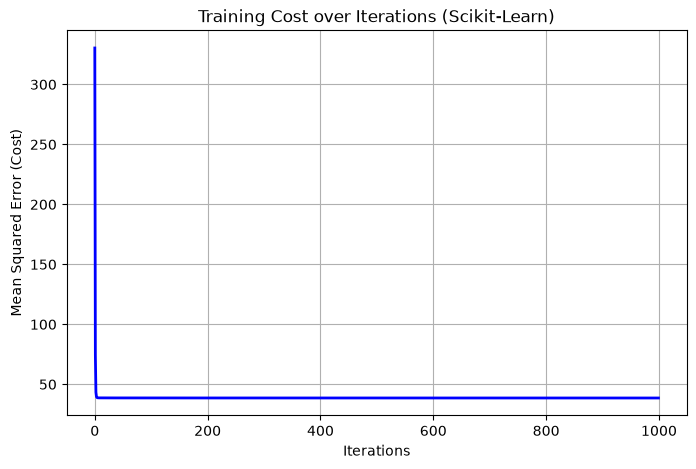

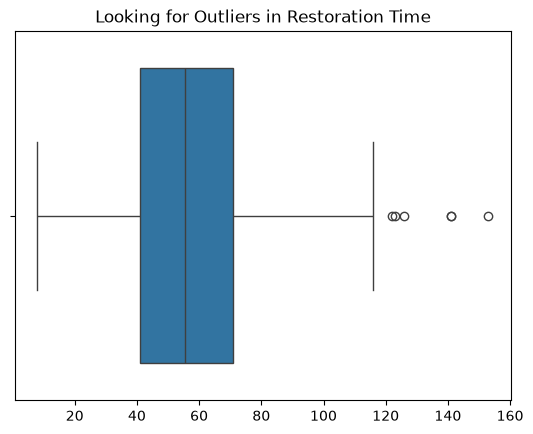

Outlier threshold: 116.0 minutes


In [37]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score,mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('grid_restoration.csv')

y = df[['Restoration_Time_Minutes']]
df = df.drop(columns=['Incident_ID','Restoration_Time_Minutes'])





df['Technician_Experience_Years'] = df[
    'Technician_Experience_Years'
].fillna(df['Technician_Experience_Years'].median())

# Categorical columns
for col in ['Fault_Category', 'Grid_Load_Level', 'Dispatch_Window']:
    df[col] = df[col].fillna(df[col].mode()[0])







nominal_categorical_column = ['Fault_Category','Dispatch_Window','Crew_Type']



load_mapping = {"Low": 0, "Medium": 1, "High": 2}
#df["Grid_Load_Level_Encoded"] = df["Grid_Load_Level"].map(load_mapping)
df["Grid_Load_Level"] = df["Grid_Load_Level"].map(load_mapping)




df_encoded = pd.get_dummies(df,columns=['Fault_Category','Dispatch_Window','Crew_Type'],drop_first=True)


bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)




X_train, X_test, y_train, y_test = train_test_split(df_encoded,y,test_size=0.20,random_state=42 )

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



model = SGDRegressor(loss="huber",epsilon=20.0,alpha=0.001,  warm_start=True , max_iter=1,tol=None,eta0=0.01,random_state=42)
n_iterations = 1000
cost_history = []

y_train_flat = y_train.values.ravel()
y_test_flat = y_test.values.ravel()
for i in range(1000):

    model.partial_fit(X_train_scaled, y_train_flat)
    
    # FIXED: Predict using scaled test data to monitor valid cost tracking
    y_pred_step = model.predict(X_test_scaled)
    cost = mean_squared_error(y_test_flat, y_pred_step) / 2
    cost_history.append(cost)

y_pred = model.predict(X_test_scaled)

rmse = np.sqrt(mean_squared_error(y_test.values.ravel(), y_pred))
mae = mean_absolute_error(y_test.values.ravel(), y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Optimized Weights (coef): {model.coef_}")

print(f"Total Model Test RMSE: {rmse:.4f} minutes")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"R² Score : {r2:.4f}")


y_distributirion = y.describe()

print(y_distributirion)



plt.figure(figsize=(8, 5))
plt.plot(range(1000), cost_history, color="b", lw=2)
plt.title("Training Cost over Iterations (Scikit-Learn)")
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (Cost)")
plt.grid(True)
plt.show()


sns.boxplot(x=y.values.ravel())
plt.title('Looking for Outliers in Restoration Time')
plt.show()







q1, q3 = 41.0, 71.0
iqr = q3 - q1
upper_bound = q3 + (1.5 * iqr)
print(f"Outlier threshold: {upper_bound} minutes")




Average Silhouette Score: 0.2935
Number of buildings in each cluster:
Cluster
0    63
1    48
2    67
Name: count, dtype: int64
  Building_ID  Cluster  Silhouette_Score
0     BLD-001        2          0.296689
1     BLD-002        2          0.212621
2     BLD-003        2          0.181616
3     BLD-004        0          0.410444
4     BLD-005        1          0.481040
Shape of reduced data: (178, 2)


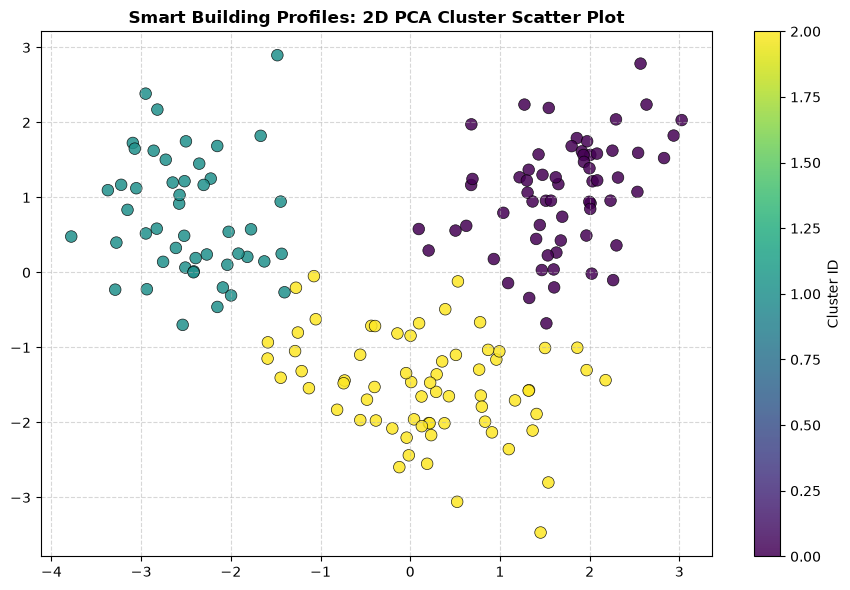

In [77]:
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_samples, silhouette_score
import pandas as pd
from sklearn.decomposition import PCA


df = pd.read_csv('smart_building_profiles.csv')

standard_cols = [
    'Avg_Indoor_Temperature_C', 'Daily_HVAC_Runtime_Hours',
 'Occupancy_Density_per_1000m2', 'Heating_Setpoint_C',
 'Insulation_Performance_Score', 'Lighting_Efficiency_Index',
 'Ventilation_Rate_ACH'
]

robust_cols = [
 'Solar_Gain_Index', 'Peak_Demand_kW',
 'Monthly_Water_Use_m3', 'Annual_Energy_Use_kWh_m2'
]

minmax_cols = [
 'Window_to_Wall_Ratio', 'Equipment_Diversity_Index'
]

preprocessor = ColumnTransformer(
transformers=[
('std', StandardScaler(), standard_cols),
 ('robust', RobustScaler(), robust_cols),
 ('minmax', MinMaxScaler(), minmax_cols)
 ],
 remainder='passthrough'
)


df_clean = df.drop(columns=['Building_ID'])



kmeans_pipeline = Pipeline(steps=[("preprocessor",preprocessor),("clusterer",KMeans(n_clusters=3, random_state=42))])
cluster_labels = kmeans_pipeline.fit_predict(df_clean)

X_scaled = kmeans_pipeline.named_steps["preprocessor"].transform(df_clean)
avg_silhouette = silhouette_score(X_scaled , cluster_labels)
print(f"Average Silhouette Score: {avg_silhouette:.4f}")

sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)


df["Silhouette_Score"] = sample_silhouette_values
df["Cluster"] = cluster_labels
cluster_counts = df['Cluster'].value_counts().sort_index()

print("Number of buildings in each cluster:")
print(cluster_counts)
print(df[["Building_ID", "Cluster", "Silhouette_Score"]].head())


pca_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),  # Scales all your features independently
        (
            "pca",
            PCA(n_components=2, random_state=42),
        ),  # Reduces dimensions to 2
    ]
)

X_reduced = pca_pipeline.fit_transform(df_clean)


print("Shape of reduced data:", X_reduced.shape)

df["PC1"] = X_reduced[:, 0]
df["PC2"] = X_reduced[:, 1]

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["PC1"],
    df["PC2"],
    c=df["Cluster"],
    cmap="viridis",
    s=70,
    alpha=0.85,
    edgecolor="k",
    linewidth=0.5,
)

plt.colorbar(scatter, label="Cluster ID")
plt.title(
    "Smart Building Profiles: 2D PCA Cluster Scatter Plot",
    fontsize=12,
    fontweight="bold",
)

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()